<!-- DRAFT: Graeme to edit -->
# Day 2 · 08 (full data) — Lab: a global model at the bottom of the hierarchy (25 min)

The original lab 05 forecasts every level of total → department → class → subclass → item
with AutoETS and reconciles them. Here the **items come from a model that has seen every
item**, the selected GFM or Chronos-2, and the levels above get a forecaster that, unlike
ETS, **sees the price and promotion plan** of the items beneath them. Because the model
forecasts every item, the upper levels are true totals, not totals of a sample.

This follows the research's phase 8, which is **experimental** (`docs/gfm_learnings.md` §8,
[100k set]). Two differences: the upper levels are chosen from ETS, ARIMAX and Chronos-2,
not the research's dynamic harmonic regression, and the GFM items come from one saved seed,
not a 3-seed mean.

| Level | Base forecast |
|---|---|
| total, department, class, subclass | chosen on validation: ETS, ARIMAX or Chronos-2 (§3) |
| item | the selected GFM, or Chronos-2; clipped at 0 and at 3× the item's largest week |

| Method | Idea |
|---|---|
| `BottomUp` | trust the items and sum them |
| `TopDown` (forecast proportions) | trust the total and split it down |
| `MiddleOut` (class) | trust the classes: sum up from them and split down |
| `MinTrace` `ols` / `wls_struct` | least-squares adjustment of every level, by the tree's shape |
| `MinTrace` `wls_var` | the same, each node weighted by its own past errors |
| `MinTrace` `mint_shrink` | the full error covariance, down to subclass; items split by share |

Goals

1. Give every node above the items its price and promotion inputs, and choose its
   forecaster on validation.
2. Forecast every item with the GFM and with Chronos-2, and measure each model's past errors.
3. Reconcile, check that the results add up, and score each method at each level.

**In the chain:** reads the selected config (`gd.selected_config()`, for its saved model)
and `00_baselines`, writes `08_reconcile`.

In [1]:
from dataclasses import replace
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from hierarchicalforecast.core import HierarchicalReconciliation
from hierarchicalforecast.methods import (BottomUpSparse, MiddleOutSparse, MinTrace,
                                          TopDownSparse)
from hierarchicalforecast.utils import aggregate
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, Naive
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import rmsse

import gd_helpers as gd
import gd_plots as gplt
import gd_price as gp

bc = gd.bc
gd.status()
gplt.use_style()

/home/gdavidson/code/time-series-forecasting-bootcamp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LOAD (read saved results) | results: results/day2_full | accelerator: gpu


<!-- DRAFT: Graeme to edit -->
## Intuition: the numbers must add up, so whom do you believe?

![Incoherent forecasts](../slides/img/hierarchy_tree.png)

Think of a budget whose line items disagree with its total. A global model is good at items:
it has seen thousands of them. It has never seen a department total, which is a different,
much smoother kind of series. A model on the total sees exactly that series, but only if it
also sees **why** the total moves: a department total jumps when half its items go on
promotion, and a forecaster without the promotion plan cannot know that is coming.
Reconciliation then decides how much to believe each level, and makes the numbers add up.

<!-- DRAFT: Graeme to edit -->
## 1. Item forecasts: the selected GFM and Chronos-2

Both models forecast **every** training series, not just the scored ones, so the upper
levels are sums of real items.

* **GFM:** the one saved seed, not the 3-seed mean on the board, because the other seeds
  were not saved (`docs/progress.md`, single-seed exceptions).
* **Chronos-2:** zero-shot with the price and promotion covariates, the final model in 10
  (`Chronos2_zs_cov` in 07). It has no seed.

In [2]:
cfg = gd.selected_config()
baselines_cfg = gd.load_config("00_baselines")
panel, train, test, data = gp.prepare(cfg, synthetic_seed=cfg.get("synthetic_seed"))
info = gplt.series_table(panel)
all_ids = sorted(panel["unique_id"].unique().to_list())
covariates = cfg["futr_exog"]
ARMS = ["GFM", "Chronos"]
RESID_WEEKS = 8 if gd.SMOKE else 52       # past weeks of one-step errors, for MinT


def gfm_items() -> pd.DataFrame:
    """The saved selected model's forecasts for every training series, clipped at 0."""
    nf = gd.load_model(cfg["saved_model"])
    every = replace(data, predict_df=gd.only(data.fit_df, all_ids),
                    futr_df=bc.to_nixtla(test, data.futr_exog).drop(columns="y"))
    with bc.Timer() as t:
        fcst = gd.predict(nf, every)          # removes the target shift
    print(f"GFM: {len(all_ids):,} series forecast in {t.seconds:.0f}s")
    col = bc.model_columns(fcst)[0]
    fcst = fcst[["unique_id", "ds", col]].rename(columns={col: "Base"})
    fcst["Base"] = fcst["Base"].clip(lower=0).astype("float32")
    return fcst


def chronos_items() -> pd.DataFrame:
    """Zero-shot Chronos-2 with the covariates, for every training series, clipped at 0."""
    hist = bc.to_nixtla(train, covariates)
    future = bc.to_nixtla(test, covariates).drop(columns="y")
    with bc.Timer() as t:
        fcst = gd.chronos_forecast(gd.chronos_pipeline(), hist, future, alias="Base")
    print(f"Chronos-2: {len(all_ids):,} series forecast in {t.seconds:.0f}s")
    fcst["Base"] = fcst["Base"].clip(lower=0).astype("float32")
    return fcst


bottom = {"GFM": gd.cached("08_bottom_forecasts", gfm_items),
          "Chronos": gd.cached("08_bottom_chronos", chronos_items)}
for arm in ARMS:
    bottom[arm]["ds"] = pd.to_datetime(bottom[arm]["ds"])
print({arm: f"{fc['unique_id'].nunique():,} items" for arm, fc in bottom.items()})

{'GFM': '17,241 items', 'Chronos': '17,241 items'}


<!-- DRAFT: Graeme to edit -->
### A guard: cap each item at a multiple of its largest training week

The eval sample hides a problem that sums over every item expose. On the first full run a
handful of the 17,000 GFM item forecasts exploded (one item that sells ≈130 units a week was
forecast at millions), and on its own that put the bottom-up store total ≈ 47% too high.
05c traced most of it to bad prices and the robust scaler, and the selected model now has
cleaned prices, a scaler floor and an input clip (`docs/stability_choices.md`). One rare
blow-up inside the network is left: in this saved seed, a best seller (`6653_S1`). So we
still cap each item's forecast at `CAP` times its largest training week, for both models.
Real sales above 3× that happened in ≈ 0.5% of test weeks, so the cap seldom cuts a real
spike. The table shows how many it touches.

In [3]:
CAP = 3                     # item forecast ceiling, as a multiple of its largest training week
train_max = train.group_by("unique_id").agg(pl.col("y").max().alias("train_max")).to_pandas()
capped = {}
for arm in ARMS:
    fc = bottom[arm].merge(train_max, on="unique_id", how="left")
    ceiling = CAP * fc["train_max"]
    over = fc["Base"] > ceiling
    capped[arm] = {"item_weeks": int(over.sum()),
                   "items": int(fc.loc[over, "unique_id"].nunique())}
    fc["Base"] = fc["Base"].clip(upper=ceiling).astype("float32")
    bottom[arm] = fc.drop(columns="train_max")
pd.DataFrame(capped).T

,item_weeks,items
GFM,201,57
Chronos,250,44


<!-- DRAFT: Graeme to edit -->
## 2. Build the hierarchy

As in the original lab. Items without a subclass cannot be placed and are left out (the cell
prints how many, and how many of them are scored). The summing matrix is kept **sparse**:
with ≈19,000 nodes and ≈17,000 items, a dense one would take several GB.

In [4]:
LEVEL_COLS = {
    "total": pl.lit("Total"),
    "department": pl.format("D{}", pl.col("department_id")),
    "class": pl.format("C{}", pl.col("class_id")),
    "subclass": pl.format("S{}", pl.col("subclass_id")),
}


def placed_items(frame: pl.DataFrame) -> pl.DataFrame:
    """The items with a subclass, with their hierarchy columns, sales and price inputs."""
    return frame.filter(pl.col("subclass_id") > 0).select(
        [expr.alias(name) for name, expr in LEVEL_COLS.items()]
        + ["unique_id", "ds", "y"] + gp.NODE_COVARIATES)


placed = placed_items(panel)
unplaced = set(panel["unique_id"].unique()) - set(placed["unique_id"].unique())
n_series = panel["unique_id"].n_unique()
n_scored = len(unplaced & set(gd.eval_ids()))
print(f"{len(unplaced):,} of {n_series:,} items have no subclass and are left out "
      f"({n_scored} of them scored)")
df = placed.select(list(LEVEL_COLS) + [pl.col("unique_id").alias("item"), "ds", "y"]).to_pandas()
df["ds"] = pd.to_datetime(df["ds"])

spec = [
    ["total"],
    ["total", "department"],
    ["total", "department", "class"],
    ["total", "department", "class", "subclass"],
    ["total", "department", "class", "subclass", "item"],
]
Y_df, S, tags = aggregate(df, spec, sparse_s=True)
LEVELS = [key.split("/")[-1] for key in tags]
print({level: len(ids) for level, ids in zip(LEVELS, tags.values())})

test_start = pd.Timestamp(bc.TEST_START)
valid_start = pd.Timestamp(bc.VALID_START)
Y_train = Y_df[Y_df["ds"] < test_start]
Y_test = Y_df[Y_df["ds"] >= test_start]
items = tags["total/department/class/subclass/item"]
item_path = pd.Series(items, index=[p.split("/")[-1] for p in items])
subclass_of = pd.Series([p.rsplit("/", 1)[0] for p in items], index=items)
level_of = {}
for key, uids in tags.items():
    for uid in uids:
        level_of[uid] = key.split("/")[-1]
upper_ids = [uid for uid, level in level_of.items() if level != "item"]
UPPER_LEVELS = LEVELS[:-1]

25 of 17,241 items have no subclass and are left out (3 of them scored)


{'total': 1, 'department': 148, 'class': 502, 'subclass': 1467, 'item': 17216}


<!-- DRAFT: Graeme to edit -->
## 3. The nodes above the items: price, promotion and events

ETS on a department total sees only the total's past. But the shop plans each item's price
and promotions for the forecast weeks, so every node can be told what is coming. For each
node and week we take its items' values, each weighted by the item's mean weekly sales
over the training weeks (`gp.aggregate_covariates`):

* `promo`: the share of the node's usual sales on promotion that week;
* `discount_depth`: their average discount depth;
* `price_index`: their average price against each item's reference price;
* one dummy per retail event week (Good Friday, Anzac Day, Mother's Day, Christmas), the
  same for every node.

For the validation window, the weights and the reference prices use only the weeks before
`VALID_START`.

In [5]:
NODE_X = gp.NODE_COVARIATES + gp.EVENT_COLS
panel_valid = gp.prepare(cfg, synthetic_seed=cfg.get("synthetic_seed"),
                         cutoff=bc.VALID_START)[0]


def node_frame(item_frame: pl.DataFrame, cutoff) -> pd.DataFrame:
    """Every upper node's sales and aggregated inputs, one row per week."""
    cov = gp.aggregate_covariates(item_frame, spec[:-1], cutoff=cutoff)
    cov["ds"] = pd.to_datetime(cov["ds"])
    nodes = Y_df[Y_df["unique_id"].isin(set(upper_ids))]
    return nodes.merge(cov, on=["unique_id", "ds"], how="left")


nodes_test = node_frame(placed, bc.TEST_START)
nodes_valid = node_frame(placed_items(panel_valid), bc.VALID_START)
print(f"{nodes_test['unique_id'].nunique():,} upper nodes | inputs: {NODE_X}")
nodes_test[nodes_test["unique_id"] == "Total"].tail(bc.H + 4).round(3)

2,118 upper nodes | inputs: ['promo', 'discount_depth', 'price_index', 'ev_easter', 'ev_anzac', 'ev_mothers_day', 'ev_christmas']


,unique_id,ds,y,promo,discount_depth,price_index,ev_easter,ev_anzac,ev_mothers_day,ev_christmas
89,Total,2025-03-19,69774199.93,0.349,0.035,0.999,0.0,0.0,0.0,0.0
90,Total,2025-03-26,70907396.65,0.342,0.040,0.991,0.0,0.0,0.0,0.0
91,Total,2025-04-02,69168122.15,0.350,0.039,0.994,0.0,0.0,0.0,0.0
92,Total,2025-04-09,71101744.07,0.355,0.037,0.996,0.0,0.0,0.0,0.0
93,Total,2025-04-16,74495461.18,0.366,0.038,0.988,1.0,0.0,0.0,0.0
94,Total,2025-04-23,68118220.35,0.354,0.035,0.994,0.0,1.0,0.0,0.0
95,Total,2025-04-30,59470289.50,0.333,0.034,1.001,0.0,0.0,0.0,0.0
96,Total,2025-05-07,68525494.96,0.340,0.033,0.995,0.0,0.0,1.0,0.0
97,Total,2025-05-14,70487876.48,0.330,0.034,1.001,0.0,0.0,0.0,0.0
98,Total,2025-05-21,69175714.54,0.337,0.036,0.998,0.0,0.0,0.0,0.0


<!-- DRAFT: Graeme to edit -->
### Three candidate forecasters, chosen on validation

* **ETS** (`AutoETS(season_length=1)`): the original lab's choice, with no inputs. The
  reference.
* **ARIMAX** (`AutoARIMA(season_length=1)` with the inputs above as regressors): the
  classical way to add a promotion plan to a time-series model. ETS is the fallback when a
  fit fails.
* **Chronos-2** with the same inputs as known covariates, zero-shot.

`season_length=1` because the aggregates have under two years of history, too short for a
yearly season; the event dummies carry the big calendar weeks instead.

**The rule, written before the results:** each candidate forecasts every upper node over
the validation window. The one with the smallest **worst-level ratio** wins: the largest,
over total to subclass, of its median RMSSE divided by ETS's. Ties within 1% go to the
simpler model, in the order ETS, ARIMAX, Chronos-2. Only the winner forecasts the test
window for reconciliation; ETS is scored on test too, as the reference.

In [6]:
UPPER_MODELS = ["ETS", "ARIMAX", "Chronos"]


def stats_model(name: str) -> StatsForecast:
    """The StatsForecast object for ``ETS`` or ``ARIMAX``."""
    if name == "ETS":
        return StatsForecast(models=[AutoETS(season_length=1)], freq=bc.FREQ,
                             n_jobs=gd.N_JOBS, fallback_model=Naive())
    return StatsForecast(models=[AutoARIMA(season_length=1)], freq=bc.FREQ, n_jobs=gd.N_JOBS,
                         fallback_model=AutoETS(season_length=1))


def upper_forecast(name: str, frame: pd.DataFrame, cutoff) -> pd.DataFrame:
    """``name``'s forecasts of the ``H`` weeks from ``cutoff`` for every node in ``frame``."""
    cutoff = pd.Timestamp(cutoff)
    hist = frame[frame["ds"] < cutoff]
    weeks = np.sort(frame.loc[frame["ds"] >= cutoff, "ds"].unique())[:bc.H]
    futr = frame[frame["ds"].isin(weeks)][["unique_id", "ds"] + NODE_X]
    with bc.Timer() as t:
        if name == "ETS":
            fc = stats_model(name).forecast(df=hist[["unique_id", "ds", "y"]], h=bc.H)
        elif name == "ARIMAX":
            fc = stats_model(name).forecast(df=hist[["unique_id", "ds", "y"] + NODE_X], h=bc.H,
                                            X_df=futr)
        else:
            fc = gd.chronos_forecast(gd.chronos_pipeline(), hist[["unique_id", "ds", "y"]
                                                                 + NODE_X], futr, alias="Base")
    print(f"{name}: {hist['unique_id'].nunique():,} nodes forecast in {t.seconds:.0f}s")
    fc = fc.reset_index() if "unique_id" not in fc.columns else fc
    fc = fc.rename(columns={"AutoETS": "Base", "AutoARIMA": "Base"})
    fc["ds"] = pd.to_datetime(fc["ds"])
    fc["Base"] = fc["Base"].clip(lower=0)
    return fc[["unique_id", "ds", "Base"]]


def level_scores(fcst: pd.DataFrame, actual: pd.DataFrame, history: pd.DataFrame,
                 cols: list[str]) -> pd.DataFrame:
    """Median RMSSE (one-step naive scale) of ``cols`` at each level."""
    scored = fcst.merge(actual[["unique_id", "ds", "y"]], on=["unique_id", "ds"])
    ev = evaluate(scored, metrics=[partial(rmsse, seasonality=1)], models=cols,
                  train_df=history[["unique_id", "ds", "y"]])
    ev["level"] = ev["unique_id"].map(level_of)
    return ev.groupby("level")[cols].median()


valid_hist = nodes_valid[nodes_valid["ds"] < valid_start]
valid_truth = nodes_valid[(nodes_valid["ds"] >= valid_start) & (nodes_valid["ds"] < test_start)]
valid_fc = None
for name in UPPER_MODELS:
    fc = gd.cached(f"08_upper_valid_{name}",
                   partial(upper_forecast, name, nodes_valid, bc.VALID_START))
    fc = fc.assign(ds=pd.to_datetime(fc["ds"])).rename(columns={"Base": name})
    valid_fc = fc if valid_fc is None else valid_fc.merge(fc, on=["unique_id", "ds"])
upper_valid = level_scores(valid_fc, valid_truth, valid_hist, UPPER_MODELS).loc[UPPER_LEVELS]
upper_valid_ratio = upper_valid.div(upper_valid["ETS"], axis=0)
upper_worst = upper_valid_ratio.max()
UPPER_TIE = 1.01
upper_tied = upper_worst[upper_worst <= upper_worst.min() * UPPER_TIE].index
upper_model = next(m for m in UPPER_MODELS if m in upper_tied)
print(f"worst-level ratio to ETS: {upper_worst.round(3).to_dict()} | chosen: {upper_model}")
upper_valid.round(3)

worst-level ratio to ETS: {'ETS': 1.0, 'ARIMAX': 2.407, 'Chronos': 1.046} | chosen: ETS


,ETS,ARIMAX,Chronos
level,,,
total,0.574,1.383,0.601
department,1.003,0.771,0.720
class,0.987,0.785,0.716
subclass,1.022,0.804,0.754


In [7]:
upper_valid_ratio.round(3)

,ETS,ARIMAX,Chronos
level,,,
total,1.0,2.407,1.046
department,1.0,0.769,0.718
class,1.0,0.795,0.725
subclass,1.0,0.787,0.738


<!-- DRAFT: Graeme to edit -->
### Reading the result

* The first table is each candidate's median RMSSE per level on validation; the second
  divides by ETS's, so below 1 the candidate beat ETS at that level.
* The validation window (January to mid-April) holds no event week, so it tests the
  promotion inputs more than the event dummies. The test window opens with Good Friday,
  Anzac Day and Mother's Day.
* **ETS is chosen, by a narrow and particular margin.** Chronos-2 with the nodes' price and
  promotion inputs beats ETS by ≈ 25–30% at department, class and subclass (0.72 against
  1.00), but is 5% worse at the total (0.601 against 0.574). The rule judges each model by its
  worst level, so that 5% decides it.
* **ARIMAX fails at the total** (1.38, more than twice ETS's error) while beating ETS below
  it. One series with a short history and seven regressors is easy to overfit.
* The upper model matters only to the methods that use the upper forecasts. BottomUp, which
  both item models choose in section 8, ignores them.

*Exact numbers vary with seed and hardware.*

In [8]:
upper = gd.cached(f"08_upper_base_{upper_model}",
                  partial(upper_forecast, upper_model, nodes_test, bc.TEST_START))
upper["ds"] = pd.to_datetime(upper["ds"])
upper_ets = gd.cached("08_upper_base_ETS", partial(upper_forecast, "ETS", nodes_test,
                                                   bc.TEST_START))
upper_ets["ds"] = pd.to_datetime(upper_ets["ds"])
upper_both = upper_ets.rename(columns={"Base": "ETS"}).merge(
    upper.rename(columns={"Base": f"{upper_model} (chosen)"}), on=["unique_id", "ds"])
upper_cols = [c for c in upper_both.columns if c not in ("unique_id", "ds")]
upper_test = level_scores(upper_both, Y_test, Y_train, upper_cols).loc[UPPER_LEVELS]
upper_test.round(3)

,ETS,ETS (chosen)
level,,
total,0.891,0.891
department,0.964,0.964
class,0.911,0.911
subclass,0.893,0.893


<!-- DRAFT: Graeme to edit -->
The same comparison on the test window, report only. When the chosen model is ETS, the two
columns are the same.

<!-- DRAFT: Graeme to edit -->
## 4. Past errors for MinT

MinT weights each node by how wrong its forecasts usually are. That needs each base
forecaster's errors on weeks it had not seen: we forecast one week ahead from each of the
last `RESID_WEEKS` training weeks (`gd.rolling_one_step`), so each model sees only the weeks
before the one it forecasts.

* **GFM:** the saved model, fed each item's history up to that week. It was trained on all
  these weeks, so its errors are in-sample and somewhat flattering.
* **Chronos-2:** reads the history in context; nothing to fit, so these are honest errors.
* **ETS, ARIMAX:** their one-step fitted values, which is the same thing for a model refitted
  on each history.

Each set is cached separately. A node whose forecast always equals its sales (an item that
never sold, forecast at 0) gets a tiny spread (`gd.floor_residual_sd`), as MinT divides by
each node's error variance.

In [9]:
train_weeks = np.sort(Y_train["ds"].unique())
origins = pd.to_datetime(train_weeks[-RESID_WEEKS:])
gfm_frame = pd.concat([gd.only(data.fit_df, all_ids)[["unique_id", "ds", "y"] + data.futr_exog],
                       bc.to_nixtla(test, data.futr_exog)], ignore_index=True)
chronos_frame = bc.to_nixtla(panel, covariates)


def gfm_one_step() -> pd.DataFrame:
    """The saved GFM's one-week-ahead forecasts of every item from each origin."""
    nf = gd.load_model(cfg["saved_model"])

    def predict(hist, futr):
        fc = gd.predict(nf, replace(data, predict_df=hist, futr_df=futr))
        return fc.rename(columns={bc.model_columns(fc)[0]: "yhat"})

    with bc.Timer() as t:
        out = gd.rolling_one_step(predict, gfm_frame, origins)
    print(f"GFM: {len(origins)} origins in {t.seconds / 60:.1f} min")
    return out


def chronos_one_step(frame: pd.DataFrame, x_cols: list[str]):
    """Chronos-2's one-week-ahead forecasts of every series in ``frame`` from each origin."""
    def compute() -> pd.DataFrame:
        pipe = gd.chronos_pipeline()

        def predict(hist, futr):
            first = futr[futr["ds"] == futr["ds"].min()][["unique_id", "ds"] + x_cols]
            return gd.chronos_forecast(pipe, hist[["unique_id", "ds", "y"] + x_cols], first,
                                       alias="yhat", h=1)

        with bc.Timer() as t:
            out = gd.rolling_one_step(predict, frame, origins)
        print(f"Chronos-2: {len(origins)} origins in {t.seconds / 60:.1f} min")
        return out
    return compute


def stats_fitted(name: str) -> pd.DataFrame:
    """ETS's or ARIMAX's one-step fitted values over the training weeks, every upper node."""
    hist = nodes_test[nodes_test["ds"] < test_start]
    cols = ["unique_id", "ds", "y"] + (NODE_X if name == "ARIMAX" else [])
    sf = stats_model(name)
    if name == "ARIMAX":
        futr = nodes_test[nodes_test["ds"] >= test_start][["unique_id", "ds"] + NODE_X]
        sf.forecast(df=hist[cols], h=bc.H, X_df=futr, fitted=True)
    else:
        sf.forecast(df=hist[cols], h=bc.H, fitted=True)
    fitted = sf.forecast_fitted_values()
    fitted = fitted.reset_index() if "unique_id" not in fitted.columns else fitted
    model_col = [c for c in fitted.columns if c.startswith("Auto")][0]
    return fitted.rename(columns={model_col: "yhat"})[["unique_id", "ds", "yhat"]]


item_one_step = {
    "GFM": gd.cached("08_resid_GFM", gfm_one_step),
    "Chronos": gd.cached("08_resid_Chronos", chronos_one_step(chronos_frame, covariates)),
}
if upper_model == "Chronos":
    compute_upper = chronos_one_step(nodes_test, NODE_X)
else:
    compute_upper = partial(stats_fitted, upper_model)
upper_one_step = gd.cached(f"08_resid_upper_{upper_model}", compute_upper)


def insample(arm: str) -> pd.DataFrame:
    """Every node's one-step forecast (``Base``) and sales (``y``) over the origin weeks."""
    item_fc = item_one_step[arm].copy()
    item_fc = item_fc[item_fc["unique_id"].isin(item_path.index)]
    item_fc["unique_id"] = item_fc["unique_id"].map(item_path)
    fc = pd.concat([upper_one_step, item_fc], ignore_index=True)
    fc["ds"] = pd.to_datetime(fc["ds"])
    fc = fc[fc["ds"].isin(origins)].rename(columns={"yhat": "Base"})
    fc["Base"] = fc["Base"].clip(lower=0)
    out = Y_df[Y_df["ds"].isin(origins)].merge(fc, on=["unique_id", "ds"], how="left")
    out["Base"] = out["Base"].fillna(0.0)
    return gd.floor_residual_sd(out)


past = {arm: insample(arm) for arm in ARMS}
errors = pd.DataFrame({arm: (p.assign(level=p["unique_id"].map(level_of),
                                      ae=(p["y"] - p["Base"]).abs())
                              .groupby("level")["ae"].mean())
                       for arm, p in past.items()}).loc[LEVELS]
errors.round(2)

,GFM,Chronos
level,,
total,2481675.08,2481675.08
department,42621.95,42621.95
class,18068.59,18068.59
subclass,7975.94,7975.94
item,702.09,687.09


<!-- DRAFT: Graeme to edit -->
Mean absolute one-step error per level, in units per week: the item rows differ by item
model; the upper rows are the chosen upper model in both columns.

<!-- DRAFT: Graeme to edit -->
## 5. Reconcile

The sparse versions of the original lab's methods, plus the two that need past errors:

* `MinTrace(wls_var)` on the full tree weights each node by its own error variance.
* `MinTrace(mint_shrink)` also uses how the errors move together, a 2,118 × 2,118 covariance
  on the tree down to subclass (a 19,000 × 19,000 one on the full tree would not fit). Its
  subclass base is the items' forecasts summed, so the item model still drives the bottom;
  each reconciled subclass is then split back to its items by their forecast shares
  (`gd.split_by_share`). It is called `MinT-shrink-sub` below.
* `MiddleOut` uses the class level. The research preferred MiddleOut (§8).

Each item model is reconciled with the chosen upper model.

The three sparse MinT methods use `gd.MinTraceDirect`: the library's method and weights with
an exact solve. The library's iterative solver ignores whether it converged; under `wls_var`,
where error variances here span many orders of magnitude, it stopped early and
returned forecasts in the millions.

In [10]:
reconcilers = [
    BottomUpSparse(),
    TopDownSparse(method="forecast_proportions"),
    MiddleOutSparse(middle_level="total/department/class", top_down_method="forecast_proportions"),
    gd.MinTraceDirect(method="ols"),
    gd.MinTraceDirect(method="wls_struct"),
    gd.MinTraceDirect(method="wls_var"),
]
SHORT = {"Base": "Base (incoherent)", "Base/BottomUpSparse": "BottomUp",
         "Base/TopDownSparse_method-forecast_proportions": "TopDown",
         "Base/MiddleOutSparse_middle_level-total/department/class_top_down_method-"
         "forecast_proportions": "MiddleOut",
         "Base/MinTraceDirect_method-ols": "MinT-ols",
         "Base/MinTraceDirect_method-wls_struct": "MinT-wls_struct",
         "Base/MinTraceDirect_method-wls_var": "MinT-wls_var"}
order = {uid: i for i, uid in enumerate(S.row_labels)}       # same order as the summing matrix

sub_df = df.groupby(list(LEVEL_COLS) + ["ds"], as_index=False)["y"].sum()
_, S_sub, tags_sub = aggregate(sub_df, spec[:-1])


def in_order(frame: pd.DataFrame, rank: dict) -> pd.DataFrame:
    """``frame`` sorted by node in ``rank``'s order, then by week."""
    return (frame.assign(_o=frame["unique_id"].map(rank)).sort_values(["_o", "ds"])
            .drop(columns="_o").reset_index(drop=True))


def to_subclass(frame: pd.DataFrame) -> pd.DataFrame:
    """Upper rows as they are, item rows summed into their subclass."""
    is_item = frame["unique_id"].map(level_of) == "item"
    summed = (frame[is_item].assign(unique_id=frame.loc[is_item, "unique_id"].map(subclass_of))
              .groupby(["unique_id", "ds"], as_index=False).sum(numeric_only=True))
    upper_rows = frame[~is_item & (frame["unique_id"].map(level_of) != "subclass")]
    return pd.concat([upper_rows, summed], ignore_index=True)


def reconcile(arm: str) -> tuple[pd.DataFrame, float]:
    """Every method's reconciled forecasts for ``arm``'s items under the chosen upper model."""
    item_base = bottom[arm][bottom[arm]["unique_id"].isin(item_path.index)].copy()
    item_base["unique_id"] = item_base["unique_id"].map(item_path)
    Y_hat = in_order(pd.concat([upper, item_base], ignore_index=True), order)
    with bc.Timer() as t:
        rec = HierarchicalReconciliation(reconcilers=reconcilers).reconcile(
            Y_hat_df=Y_hat, S_df=S, tags=tags, Y_df=in_order(past[arm], order))
        rec = rec.rename(columns=SHORT)

        sub_order = {uid: i for i, uid in enumerate(S_sub["unique_id"])}
        sub_rec = HierarchicalReconciliation(reconcilers=[MinTrace(method="mint_shrink")])
        sub_rec = sub_rec.reconcile(Y_hat_df=in_order(to_subclass(Y_hat), sub_order),
                                    S_df=S_sub, tags=tags_sub,
                                    Y_df=in_order(to_subclass(past[arm]), sub_order))
        sub_rec = sub_rec.rename(columns={"Base/MinTrace_method-mint_shrink": "MinT-shrink-sub"})
        subclass_rows = sub_rec[sub_rec["unique_id"].map(level_of) == "subclass"]
        item_rows = gd.split_by_share(subclass_rows, item_base, subclass_of, "MinT-shrink-sub")
        shrink = pd.concat([sub_rec[["unique_id", "ds", "MinT-shrink-sub"]], item_rows])
        rec = rec.merge(shrink, on=["unique_id", "ds"], how="left")
    return rec, t.seconds


Y_rec = {}
rec_seconds = {}
for arm in ARMS:
    Y_rec[arm], rec_seconds[arm] = reconcile(arm)
    print(f"{arm}: reconciled in {rec_seconds[arm]:.1f}s")
methods = [c for c in Y_rec[ARMS[0]].columns
           if c in list(SHORT.values()) + ["MinT-shrink-sub"]]
methods

GFM: reconciled in 17.2s


Chronos: reconciled in 17.4s


['Base (incoherent)',
 'BottomUp',
 'TopDown',
 'MiddleOut',
 'MinT-ols',
 'MinT-wls_struct',
 'MinT-wls_var',
 'MinT-shrink-sub']

<!-- DRAFT: Graeme to edit -->
### Coherence check: does everything add up?

Two checks per method: the original lab's (items sum to the total) and a stricter one (every
node equals the sum of its items, via the summing matrix). A method that fails is dropped.

In [11]:
def coherence(Y_rec: pd.DataFrame, method: str) -> dict:
    """Largest gap between the total and its items, and between any node and its items."""
    wide = Y_rec.pivot(index="unique_id", columns="ds", values=method)
    all_nodes = wide.loc[S.row_labels].to_numpy()
    bottom_nodes = wide.loc[S.col_labels].to_numpy()
    total = wide.loc["Total"].to_numpy()
    return {"max |total - sum of items|": float(np.abs(total - bottom_nodes.sum(axis=0)).max()),
            "max |node - sum of its items|": float(np.abs(all_nodes - S.to_csr() @ bottom_nodes)
                                                   .max())}


COHERENCE_TOL = 1e-6        # allowed gap, as a share of the average weekly total
total_size = Y_train[Y_train["unique_id"] == "Total"]["y"].mean()
tolerance = COHERENCE_TOL * total_size
checks = pd.concat({arm: pd.DataFrame({m: coherence(Y_rec[arm], m) for m in methods}).T
                    for arm in ARMS}, names=["items", "method"])
incoherent = sorted({m for (arm, m), row in checks.iterrows()
                     if m != "Base (incoherent)" and row.max() > tolerance})
print("fails the coherence check, dropped:", incoherent)
methods = [m for m in methods if m not in incoherent]
checks.round(4)

fails the coherence check, dropped: []


max |total - sum of items|  \
items   method                                          
GFM     Base (incoherent)                8.074858e+06   
        BottomUp                         0.000000e+00   
        TopDown                          0.000000e+00   
        MiddleOut                        0.000000e+00   
        MinT-ols                         0.000000e+00   
        MinT-wls_struct                  0.000000e+00   
        MinT-wls_var                     0.000000e+00   
        MinT-shrink-sub                  3.375000e-01   
Chronos Base (incoherent)                3.230802e+06   
        BottomUp                         0.000000e+00   
        TopDown                          0.000000e+00   
        MiddleOut                        0.000000e+00   
        MinT-ols                         0.000000e+00   
        MinT-wls_struct                  0.000000e+00   
        MinT-wls_var                     0.000000e+00   
        MinT-shrink-sub                  2.774000e-01   

                           max |node - sum of its items|  
items   method                                            
GFM     Base (incoherent)                   8.074858e+06  
        BottomUp                            0.000000e+00  
        TopDown                             0.000000e+00  
        MiddleOut                           0.000000e+00  
        MinT-ols                            0.000000e+00  
        MinT-wls_struct                     0.000000e+00  
        MinT-wls_var                        0.000000e+00  
        MinT-shrink-sub                     3.375000e-01  
Chronos Base (incoherent)                   3.230802e+06  
        BottomUp                            0.000000e+00  
        TopDown                             0.000000e+00  
        MiddleOut                           0.000000e+00  
        MinT-ols                            0.000000e+00  
        MinT-wls_struct                     0.000000e+00  
        MinT-wls_var                        0.000000e+00  
        MinT-shrink-sub                     2.774000e-01

<!-- DRAFT: Graeme to edit -->
Every reconciled method should show 0, up to rounding; only the base forecasts may disagree.
In the original lab the dense `MiddleOut` failed this check, so run it whenever the library
or the hierarchy changes.

<!-- DRAFT: Graeme to edit -->
## 6. The rule, written before the results

Planning uses every level, so a method should not be bad at any of them. For each item
model we pick the coherent method whose **worst level** is best: the smallest maximum, over
the five levels, of its median RMSSE divided by that item model's base forecast. Ties within
1% go to `MiddleOut`, the research's preference, then to the simpler method.

The rule reads the test window, so the chosen method is a finding to report, not a setting
tuned for later notebooks.

<!-- DRAFT: Graeme to edit -->
## 7. Accuracy per level

RMSSE here is scaled by the one-step naive error, as in the original lab, because the
aggregates are too short for a 52-week scale. So the scores compare across levels but **not**
with the board. Forecasts are clipped at 0. Every node at each level is scored, all 17,000
items included. One table per item model: median first, then the mean.

In [12]:
by_level = {}
by_level_mean = {}
bias = {}
for arm in ARMS:
    scored = Y_rec[arm].merge(Y_test, on=["unique_id", "ds"])
    scored[methods] = scored[methods].clip(lower=0)
    ev = evaluate(scored, metrics=[partial(rmsse, seasonality=1)], models=methods,
                  train_df=Y_train)
    ev["level"] = ev["unique_id"].map(level_of)
    by_level[arm] = ev.groupby("level")[methods].median().loc[LEVELS]
    by_level_mean[arm] = ev.groupby("level")[methods].mean().loc[LEVELS]
    sums = scored.assign(level=scored["unique_id"].map(level_of)).groupby("level")
    totals = sums[methods + ["y"]].sum()
    bias[arm] = totals[methods].div(totals["y"], axis=0).sub(1).loc[LEVELS]
pd.concat(by_level, names=["items", "level"]).round(3)

Base (incoherent)  BottomUp  TopDown  MiddleOut  MinT-ols  \
items   level                                                                   
GFM     total                   0.891     0.853    0.891      1.009     0.892   
        department              0.964     0.807    0.958      0.956     1.110   
        class                   0.911     0.782    0.911      0.911     1.210   
        subclass                0.893     0.740    0.891      0.909     1.100   
        item                    0.683     0.683    0.769      0.773     0.974   
Chronos total                   0.891     0.767    0.891      1.009     0.892   
        department              0.964     0.693    0.958      0.956     1.109   
        class                   0.911     0.681    0.911      0.911     1.208   
        subclass                0.893     0.676    0.891      0.909     1.107   
        item                    0.676     0.676    0.801      0.806     1.018   

                    MinT-wls_struct  MinT-wls_var  MinT-shrink-sub  
items   level                                                       
GFM     total                 0.918         0.749            0.680  
        department            0.899         0.802            0.795  
        class                 0.873         0.764            0.756  
        subclass              0.830         0.736            0.760  
        item                  0.866         0.684            0.694  
Chronos total                 0.921         0.821            0.767  
        department            0.854         0.740            0.755  
        class                 0.839         0.713            0.742  
        subclass              0.829         0.705            0.722  
        item                  0.880         0.682            0.703

In [13]:
pd.concat(by_level_mean, names=["items", "level"]).round(3)

Base (incoherent)  BottomUp  TopDown  MiddleOut  MinT-ols  \
items   level                                                                   
GFM     total                   0.891     0.853    0.891      1.009     0.892   
        department              1.337     1.183    1.317      1.312     1.925   
        class                   1.278     1.135    1.277      1.278     2.105   
        subclass                1.295     1.150    1.302      1.307     2.094   
        item                    1.813     1.813    1.921      1.922     6.826   
Chronos total                   0.891     0.767    0.891      1.009     0.892   
        department              1.337     0.944    1.317      1.312     1.920   
        class                   1.278     0.981    1.277      1.278     2.074   
        subclass                1.295     1.019    1.302      1.307     2.154   
        item                    1.831     1.831    2.087      2.091     7.771   

                    MinT-wls_struct  MinT-wls_var  MinT-shrink-sub  
items   level                                                       
GFM     total                 0.918         0.749            0.680  
        department            1.219         1.163            1.135  
        class                 1.323         1.106            1.107  
        subclass              1.357         1.125            1.134  
        item                  5.098         1.811            1.822  
Chronos total                 0.921         0.821            0.767  
        department            1.167         1.052            1.045  
        class                 1.248         1.029            1.036  
        subclass              1.392         1.049            1.064  
        item                  5.766         1.839            1.892

<!-- DRAFT: Graeme to edit -->
Bias per level: total forecast over total actual, minus one (negative = under-forecast).

In [14]:
pd.concat(bias, names=["items", "level"]).round(3)

Base (incoherent)  BottomUp  TopDown  MiddleOut  MinT-ols  \
items   level                                                                   
GFM     total                   0.015     0.043    0.015      0.037     0.016   
        department              0.044     0.043    0.015      0.037     0.017   
        class                   0.037     0.043    0.015      0.037     0.019   
        subclass                0.032     0.043    0.015      0.037     0.022   
        item                    0.043     0.043    0.015      0.037     0.062   
Chronos total                   0.015     0.021    0.015      0.037     0.016   
        department              0.044     0.021    0.015      0.037     0.017   
        class                   0.037     0.021    0.015      0.037     0.019   
        subclass                0.032     0.021    0.015      0.037     0.022   
        item                    0.021     0.021    0.015      0.037     0.051   

                    MinT-wls_struct  MinT-wls_var  MinT-shrink-sub  
items   level                                                       
GFM     total                 0.034         0.024            0.010  
        department            0.034         0.024            0.010  
        class                 0.034         0.024            0.010  
        subclass              0.034         0.024            0.012  
        item                  0.055         0.025            0.012  
Chronos total                 0.030         0.026            0.027  
        department            0.030         0.026            0.027  
        class                 0.030         0.026            0.027  
        subclass              0.030         0.026            0.027  
        item                  0.044         0.027            0.027

<!-- DRAFT: Graeme to edit -->
The chart below puts the per-level tables on one scale, one panel per item model. Each group
of bars is a method; each bar is one level, its median RMSSE divided by the base forecast's
at that level. Left of the dotted line at 1, reconciliation helped that level; right of it,
it hurt.

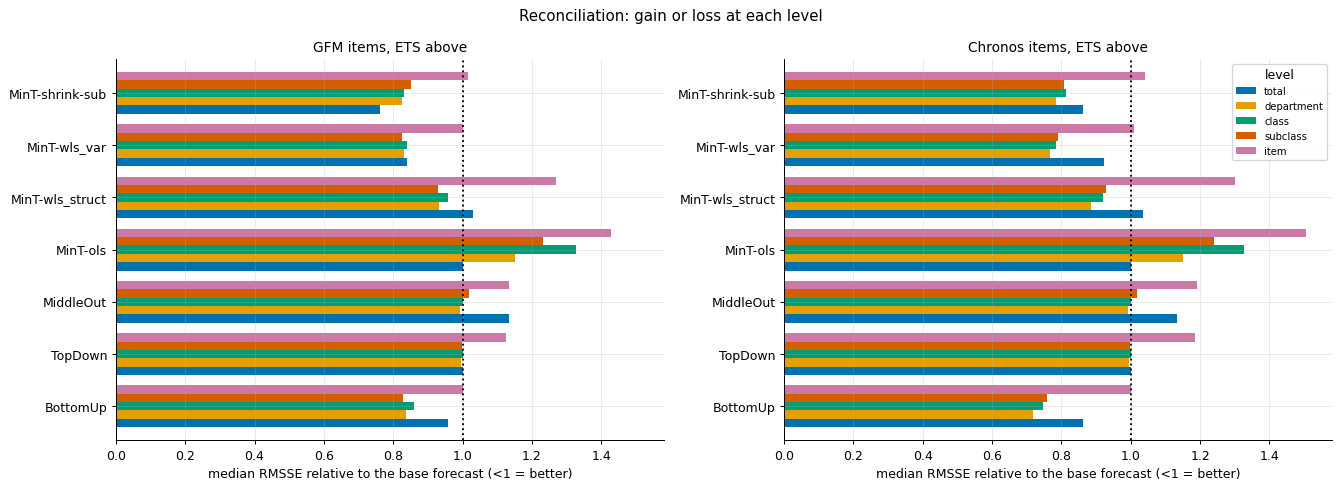

In [15]:
rel = {arm: by_level[arm].div(by_level[arm]["Base (incoherent)"], axis=0)
       .drop(columns="Base (incoherent)") for arm in ARMS}
fig, axes = plt.subplots(1, len(ARMS), figsize=(15, 5.5), sharex=True)
for ax, arm in zip(axes, ARMS):
    rel[arm].T.plot.barh(ax=ax, width=0.8, legend=ax is axes[-1])
    ax.axvline(1, color="black", ls=":")
    ax.set_xlabel("median RMSSE relative to the base forecast (<1 = better)")
    ax.set_title(f"{arm} items, {upper_model} above")
fig.suptitle("Reconciliation: gain or loss at each level")
fig.tight_layout()
plt.show()

<!-- DRAFT: Graeme to edit -->
### Reading the result

* Each method's longest bar is its worst level, which the rule uses. Expect BottomUp to leave
  the items unchanged (ratio 1) and TopDown to leave the total unchanged.
* In the original lab, with ETS items, BottomUp made the total ≈ 29% worse. With GFM items
  and ETS above, BottomUp's total was ≈ 5% better than ETS on the total itself, so every
  method that leant on ETS lost. Does a price-aware upper model change that?
* `MinT-wls_var` and `MinT-shrink-sub` weight each level by its past errors. Where they beat
  `MinT-ols`, the weights are doing the work.
* Check the bias table too: a method can win on RMSSE and still under-forecast a level.
* **BottomUp is best or close to it at every level, for both item models.** With Chronos-2
  items it is the best at every level (0.676 at item, 0.767 at the total). With GFM items it
  is the best at the item level (0.683), and within 0.012 of the best at department.
* **The weighted MinT methods win the upper levels with GFM items.** `MinT-shrink-sub` is by
  far the best at the total (0.680, against 0.853 for BottomUp) and best at department and
  class (0.795, 0.756); `MinT-wls_var` is best at subclass (0.736). Both lose a little at
  the item level (1.6% and 0.1%), and that is their worst level.
* **The GFM's saved seed is its weak spot.** One best seller (`6653_S1`) blows up in this
  seed; capped at 3× its largest week it still over-forecasts by millions of units, so the
  GFM bottom-up total is ≈ 4% too high (Chronos-2: ≈ 2%) and its item WAPE is poor, though
  the median item is fine. The 3-seed mean on the board includes this seed, so it shares
  the weak spot, capped in the same way.
* **The `wls_var` fix.** The library's sparse solver for MinT stops early without saying so
  when the error variances span many orders of magnitude, as they do here (from ≈ 0.02
  for the slowest items upwards). Its `wls_var` forecasts reached the millions, and each
  reconcile took 37 minutes.
  `gd.MinTraceDirect` solves the same equations exactly in ≈ 16 s.
* `MinT-ols` is the worst at every level below the total (≈ 1.0–1.2): it trusts the ETS
  upper forecasts as much as the items.

*Exact numbers vary with seed and hardware.*

### One subclass and its department, before and after

The subclass and department of the first high-volume example series, with GFM items:
actuals, the base forecasts (dotted), and each coherent method (dashed).

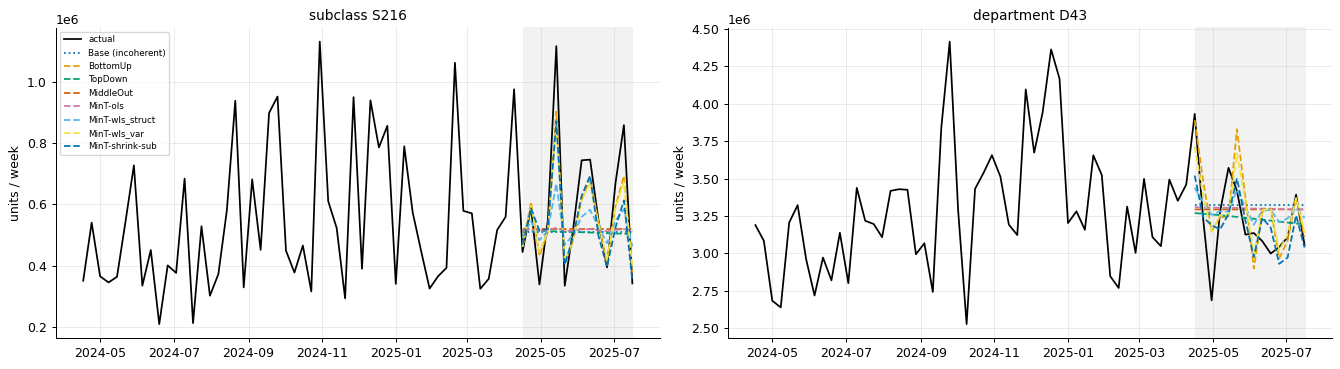

In [16]:
example = baselines_cfg["examples"]["high"][0]
path = item_path.get(example, items[0])
nodes = {"subclass": path.rsplit("/", 1)[0], "department": "/".join(path.split("/")[:2])}
start = test_start - pd.Timedelta(weeks=52)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, (level, node) in zip(axes, nodes.items()):
    hist = Y_df[(Y_df["unique_id"] == node) & (Y_df["ds"] >= start)]
    ax.plot(hist["ds"], hist["y"], color=gplt.COLOURS["actual"], lw=1.4, label="actual")
    fc = Y_rec["GFM"][Y_rec["GFM"]["unique_id"] == node]
    for i, m in enumerate(methods):
        ls = ":" if m == "Base (incoherent)" else "--"
        ax.plot(fc["ds"], fc[m], ls=ls, lw=1.4, color=gplt._colour(i), label=m)
    ax.axvspan(test_start, hist["ds"].max(), color=gplt.COLOURS["test"], zorder=0)
    ax.set(title=f"{level} {node.split('/')[-1]}", ylabel="units / week")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

<!-- DRAFT: Graeme to edit -->
## 8. Apply the rule

Each method's worst-level ratio, the tie band and the preference order from section 6, for
each item model.

In [17]:
TIE_BAND = 1.01             # within 1% of the best worst-level ratio counts as a tie
preference = ["MiddleOut", "BottomUp", "TopDown", "MinT-wls_struct", "MinT-ols",
              "MinT-wls_var", "MinT-shrink-sub"]
worst = pd.DataFrame({arm: rel[arm].max() for arm in ARMS})
chosen = {}
for arm in ARMS:
    tied = worst[arm][worst[arm] <= worst[arm].min() * TIE_BAND].index.tolist()
    chosen[arm] = next(m for m in preference if m in tied)
print(f"chosen: {chosen}")
worst.round(3)

chosen: {'GFM': 'BottomUp', 'Chronos': 'BottomUp'}


,GFM,Chronos
BottomUp,1.000,1.000
TopDown,1.127,1.184
MiddleOut,1.133,1.192
MinT-ols,1.427,1.505
MinT-wls_struct,1.269,1.301
MinT-wls_var,1.002,1.008
MinT-shrink-sub,1.016,1.040


<!-- DRAFT: Graeme to edit -->
Both item models choose **BottomUp**. With GFM items, `MinT-wls_var`'s worst level is only
0.2% behind (inside the 1% tie band), and the preference order then picks BottomUp over it.
A planner who cares most about the department and class totals would pick `MinT-wls_var`
or `MinT-shrink-sub`; the rule, which cares about every level, does not.

<!-- DRAFT: Graeme to edit -->
## 9. The item level on the board

Each item model's chosen method, at the item level for the scored series, on the board's
scale (52-week RMSSE): `HIER_GFM_<method>` and `HIER_Chronos_<method>`. When the chosen
method is BottomUp, the column is the item model itself, capped. For the GFM that is new
(one seed; the board has the 3-seed mean), but for Chronos-2 it is `Chronos2_zs_cov` again,
so a Chronos column goes on the board only if a reconciled method wins.

In [18]:
ALREADY_ON_BOARD = {"Chronos"}       # arms whose item forecasts are a board column already
item_fc = None
for arm in ARMS:
    if chosen[arm] == "BottomUp" and arm in ALREADY_ON_BOARD:
        print(f"{arm}: BottomUp is its item forecasts, already on the board; not added")
        continue
    col = f"HIER_{arm}_{chosen[arm]}"
    rows = Y_rec[arm][Y_rec[arm]["unique_id"].isin(set(items))]
    fc = rows[["unique_id", "ds", chosen[arm]]].rename(columns={chosen[arm]: col})
    fc["unique_id"] = fc["unique_id"].str.split("/").str[-1]
    item_fc = fc if item_fc is None else item_fc.merge(fc, on=["unique_id", "ds"])
item_fc = gd.only(item_fc, gd.eval_ids())
gd.save_forecasts(item_fc, "08_reconcile")
gd.record(item_fc, test, train, lab="08 hierarchy", fit_seconds=sum(rec_seconds.values()),
          notes=f"item level of the reconciled hierarchy; {upper_model} above; GFM one seed")
gd.median_board("08")

Chronos: BottomUp is its item forecasts, already on the board; not added


,model,median_rmsse,mean_rmsse,wape,n_series,lab,fit_seconds
0,T0gamma_zs_cov,0.502,1.064,0.206,1999,07b new foundation,6.068
1,Chronos2_zs_cov,0.512,1.076,0.217,1999,07 foundation,3.130
2,GFM_clean_floor,0.519,2.431,21.871,1999,05c clean + floor (3-seed mean),344.533
3,GFM_clean_floor_clip,0.520,1.078,0.399,1999,"05c clean + floor + clip, capped (3-seed mean)",357.533
4,Timestral_zs_cov,0.521,1.032,0.227,1999,07b new foundation,12.792
5,GFM_floor,0.523,1.488,6.985,1999,05c scaler floor (3-seed mean),362.700
6,HIER_GFM_BottomUp,0.526,1.060,0.409,1996,08 hierarchy,34.575
7,GFM_cluster_static,0.526,1.092,0.532,1999,06 clusters (3-seed mean),398.533
8,NHITS_recipe_mean,0.539,1.063,0.251,1999,01 recipe (3-seed mean),249.433
9,NBEATSx_B_cpi_mean,0.540,1.076,0.263,1999,04 price arms (3-seed mean),522.767


<!-- DRAFT: Graeme to edit -->
The same items next to `GFM_selected`, the 3-seed mean on the board (F2: histogram,
cumulative curve and box plot by class).

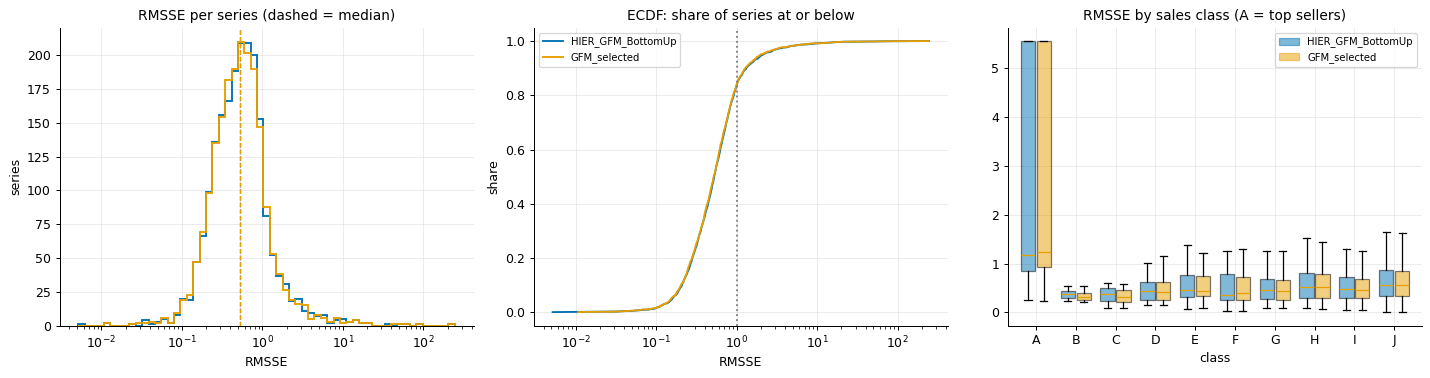

In [19]:
item_vs_board = item_fc.merge(gd.selected_forecasts(cfg), on=["unique_id", "ds"])
item_rmsse = gd.per_series(gd.score(item_vs_board, test, train))
gplt.plot_error_dist(item_rmsse, info)

In [20]:
gd.save_config("08_reconcile", {
    "selected_from": cfg.get("forecasts", "05_selected"),
    "bottom_model": cfg["saved_model"],
    "item_models": {"GFM": cfg["saved_model"], "Chronos": "Chronos2_zs_cov (zero-shot)"},
    "item_cap": {"multiple_of_train_max": CAP, **{arm: capped[arm] for arm in ARMS}},
    "upper_inputs": NODE_X,
    "upper_candidates": UPPER_MODELS,
    "upper_valid": upper_valid.round(4).to_dict("index"),
    "upper_rule": "smallest worst-level ratio to ETS (median RMSSE, validation); ties within 1% "
                  "-> ETS, ARIMAX, Chronos",
    "upper_model": upper_model,
    "upper_test": upper_test.round(4).to_dict("index"),
    "resid_weeks": RESID_WEEKS,
    "levels": {level: len(ids) for level, ids in zip(LEVELS, tags.values())},
    "methods": methods,
    "dropped_incoherent": incoherent,
    "median_rmsse_by_level": {arm: by_level[arm].round(4).to_dict("index") for arm in ARMS},
    "mean_rmsse_by_level": {arm: by_level_mean[arm].round(4).to_dict("index") for arm in ARMS},
    "bias_by_level": {arm: bias[arm].round(4).to_dict("index") for arm in ARMS},
    "worst_level_ratio": worst.round(4).to_dict(),
    "rule": "per item model: smallest worst-level ratio to base (median RMSSE); ties within 1% "
            "-> MiddleOut",
    "chosen": chosen,
    "board_columns": list(bc.model_columns(item_fc)),
})

PosixPath('/home/gdavidson/code/time-series-forecasting-bootcamp/results/day2_full/configs/08_reconcile.json')

<!-- DRAFT: Graeme to edit -->
## Discussion

* The upper model was chosen on a window with no event weeks. Would you trust its event
  dummies, each fitted on one or two past events, for Easter?
* With a strong item model, does BottomUp still win at the top? If not, look at its
  total-level bias: small item biases add up across 17,000 items.
* The GFM's past errors are in-sample, Chronos-2's are not. Which item model does that
  flatter in `MinT-wls_var`, and how?
* `MinT-shrink-sub` stops at subclass and splits by forecast shares. What does it give up
  against a full-tree MinT, and what would the full tree cost?

**Try it:** add Fourier terms (`gp.add_fourier`) to the ARIMAX regressors, delete the
`08_upper_valid_ARIMAX` table, and rerun with `GD_TRAIN=1`. Does a yearly shape help a series
with under two years of history?